<a href="https://colab.research.google.com/github/sjkim-audio/audio-dsp-lab/blob/main/notebooks/11_bacis_programiming.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
import pandas as pd

# 1. [01. Data Get] requests.get()으로 웹(GitHub)상의 공개 음원 CSV 데이터 수신 (교안 Requests 예제 1)
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
response = requests.get(url, timeout=10)

print("=== [01. Data Get] 웹 요청 상태 확인 ===")
print(f"status_code : {response.status_code}")
print(f"요청 성공 여부: {response.ok}")
print(f"바이트 크기   : {len(response.content):,} bytes")

# 2. 수신한 데이터를 로컬 CSV 파일로 저장 후 읽기 (교안 Pandas 예제 3)
csv_path = "/content/spotify_songs.csv"
with open(csv_path, "wb") as f:
    f.write(response.content)

# 실습에 필요한 4개 음향 특징 컬럼만 선택 및 결측치 제거 (300곡 샘플링)
raw_df = pd.read_csv(csv_path)
df = raw_df[["tempo", "energy", "loudness", "acousticness"]].dropna().sample(300, random_state=42)

print(f"\n[CSV 로드 완료] shape: {df.shape}")
print(df.head())

=== [01. Data Get] 웹 요청 상태 확인 ===
status_code : 200
요청 성공 여부: True
바이트 크기   : 7,971,379 bytes

[CSV 로드 완료] shape: (300, 4)
         tempo  energy  loudness  acousticness
30056  174.026   0.789    -7.717      0.004910
11827  156.371   0.661   -11.405      0.265000
23571   86.529   0.758    -5.204      0.665000
14741   90.016   0.966    -2.352      0.000006
25570   67.104   0.625    -8.212      0.035100


=== [02. SciVis] 음향 특성 상관 행렬 ===
              tempo  energy  loudness  acousticness
tempo          1.00    0.10      0.02         -0.12
energy         0.10    1.00      0.62         -0.50
loudness       0.02    0.62      1.00         -0.28
acousticness  -0.12   -0.50     -0.28          1.00


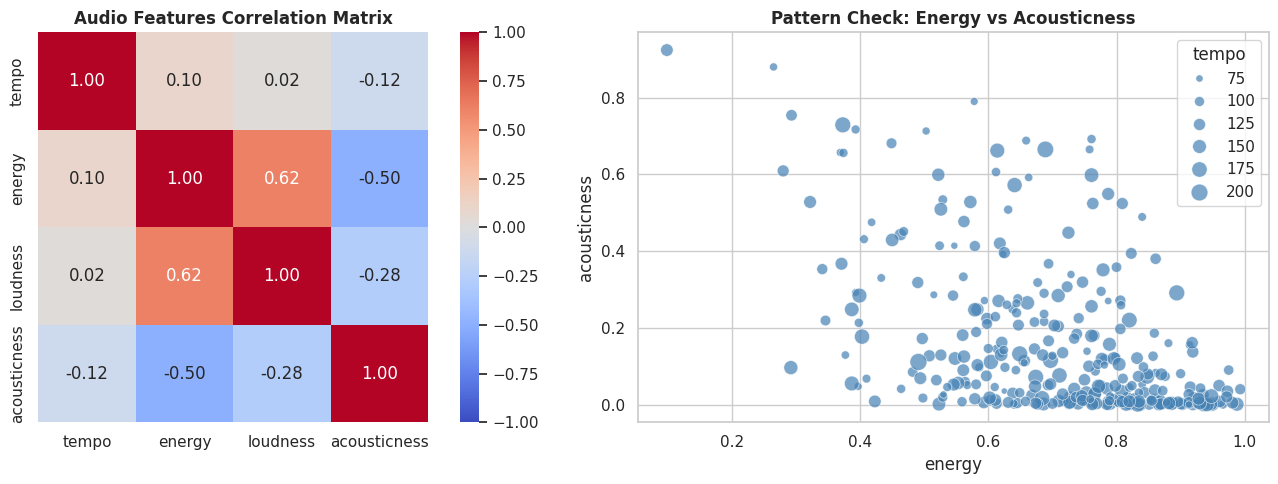

저장 완료: /content/step2_scivis.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. 상관계수 행렬 계산 (교안 Seaborn 예제 4)
corr = df.corr()
print("=== [02. SciVis] 음향 특성 상관 행렬 ===")
print(corr.round(2))

# 2. 시각화: (좌) 상관관계 히트맵 + (우) 음향 특징 산점도
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) 히트맵 (교안 Seaborn 예제 4)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Audio Features Correlation Matrix", fontweight="bold")

# (2) 산점도: Energy vs Acousticness, 점 크기=Tempo (교안 Seaborn 예제 1)
sns.scatterplot(data=df, x="energy", y="acousticness",
                size="tempo", sizes=(20, 150), color="steelblue",
                alpha=0.7, ax=axes[1])
axes[1].set_title("Pattern Check: Energy vs Acousticness", fontweight="bold")

plt.tight_layout()
save_vis = "/content/step2_scivis.png"
plt.savefig(save_vis, dpi=150, bbox_inches="tight")
plt.show()
print(f"저장 완료: {save_vis}")

=== [03. ML] K-Means 군집화 결과 ===
반복: 8, Inertia: 6.13, Silhouette: 0.4342
  군집 0: 중심=(energy=0.60, acousticness=0.14), 곡 수 n=117
  군집 1: 중심=(energy=0.84, acousticness=0.05), 곡 수 n=135
  군집 2: 중심=(energy=0.54, acousticness=0.55), 곡 수 n=48


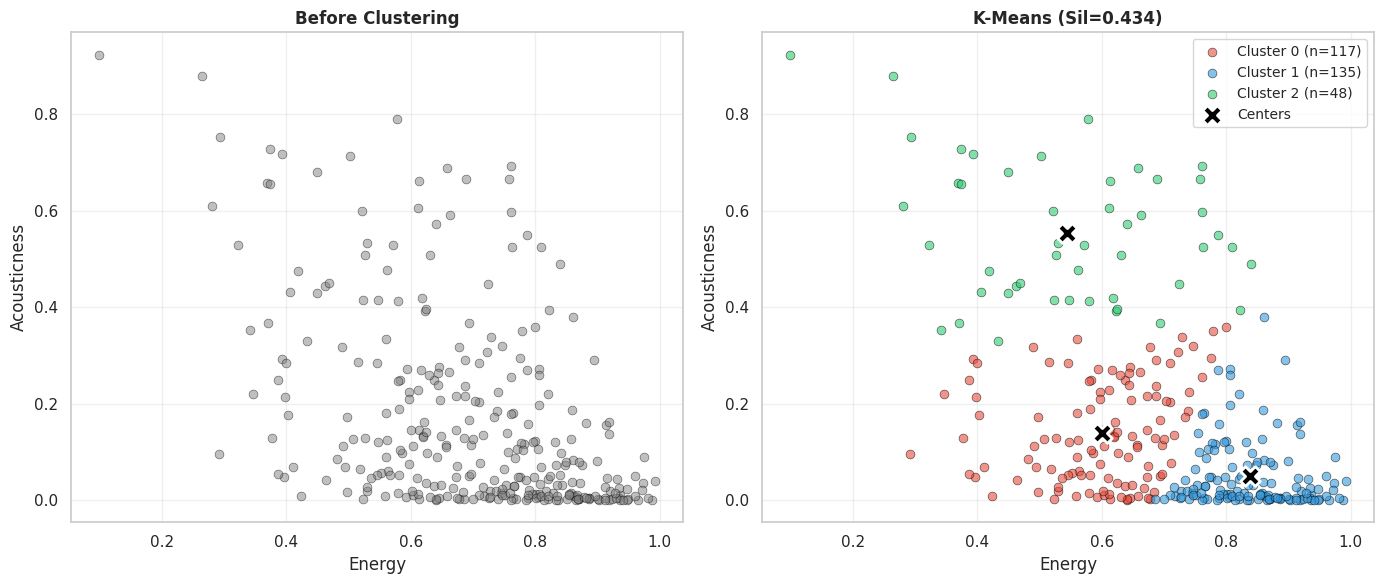

저장 완료: /content/step3_kmeans.png


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. 군집화할 2D 특징 선택 (시각화 단계에서 뚜렷한 음의 상관관계 및 3개 군집 패턴이 확인된 변수)
X = df[["energy", "acousticness"]].values

# 2. K-Means 모델 학습 (교안 scikit-learn 예제 4)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X)
centers = kmeans.cluster_centers_
sil = silhouette_score(X, y_pred)

print("=== [03. ML] K-Means 군집화 결과 ===")
print(f"반복: {kmeans.n_iter_}, Inertia: {kmeans.inertia_:.2f}, Silhouette: {sil:.4f}")
for i, c in enumerate(centers):
    print(f"  군집 {i}: 중심=(energy={c[0]:.2f}, acousticness={c[1]:.2f}), 곡 수 n={np.sum(y_pred==i)}")

# 3. 군집화 전/후 비교 시각화 (교안 scikit-learn 예제 4 동일 레이아웃)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#e74c3c', '#3498db', '#2ecc71']

# (좌) 군집화 전
axes[0].scatter(X[:, 0], X[:, 1], c='gray', alpha=0.5, s=40, edgecolors='black', lw=0.5)
axes[0].set_xlabel('Energy'); axes[0].set_ylabel('Acousticness')
axes[0].set_title('Before Clustering', fontweight='bold'); axes[0].grid(alpha=0.3)

# (우) K-Means 군집화 후
for i in range(3):
    m = (y_pred == i)
    axes[1].scatter(X[m, 0], X[m, 1], c=colors[i], alpha=0.6, s=40,
                    edgecolors='black', lw=0.5, label=f'Cluster {i} (n={m.sum()})')

axes[1].scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200,
                edgecolors='white', lw=2, zorder=10, label='Centers')
axes[1].set_xlabel('Energy'); axes[1].set_ylabel('Acousticness')
axes[1].set_title(f'K-Means (Sil={sil:.3f})', fontweight='bold')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.tight_layout()
save_ml = "/content/step3_kmeans.png"
plt.savefig(save_ml, dpi=150, bbox_inches="tight")
plt.show()
print(f"저장 완료: {save_ml}")

In [ ]:
import requests
import pandas as pd

# 1. [01. Data Get] requests.get()으로 웹상의 공개 음원 CSV 수신 (교안 Requests 예제 1)
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
response = requests.get(url, timeout=10)

print("=== [01. Data Get - 2차 실험] 웹 요청 상태 확인 ===")
print(f"status_code : {response.status_code}")
print(f"요청 성공 여부: {response.ok}")

# 2. 로컬 CSV로 저장 후 읽기 (교안 Pandas 예제 3)
csv_path = "/content/spotify_songs.csv"
with open(csv_path, "wb") as f:
    f.write(response.content)

raw_df = pd.read_csv(csv_path)

# 3. 성향이 반대되는 2개 장르('edm', 'r&b')만 조건 필터링 (교안 Pandas 예제 2)
target_genres = ["edm", "r&b"]
filtered_df = raw_df[raw_df["playlist_genre"].isin(target_genres)]

# 실습용 4개 음향 특징 컬럼 선택 및 300곡 샘플링 (장르별 150곡씩 균등 추출)
df_2nd = (
    filtered_df[["tempo", "energy", "loudness", "acousticness"]]
    .dropna()
    .sample(300, random_state=42)
)

print(f"\n[필터링 완료] 선택 장르: {target_genres}, shape: {df_2nd.shape}")
print(df_2nd.head())

=== [01. Data Get - 2차 실험] 웹 요청 상태 확인 ===
status_code : 200
요청 성공 여부: True

[필터링 완료] 선택 장르: ['edm', 'r&b'], shape: (300, 4)
         tempo  energy  loudness  acousticness
26648   84.161   0.370   -13.115       0.10800
29401  127.969   0.799    -4.705       0.00432
31159  123.005   0.961    -4.712       0.00112
30773  127.918   0.728    -6.391       0.03130
31382  100.005   0.639    -6.754       0.57100


=== [02. SciVis - 2차 실험] 음향 특성 상관 행렬 ===
              tempo  energy  loudness  acousticness
tempo          1.00    0.23      0.21         -0.14
energy         0.23    1.00      0.68         -0.52
loudness       0.21    0.68      1.00         -0.29
acousticness  -0.14   -0.52     -0.29          1.00


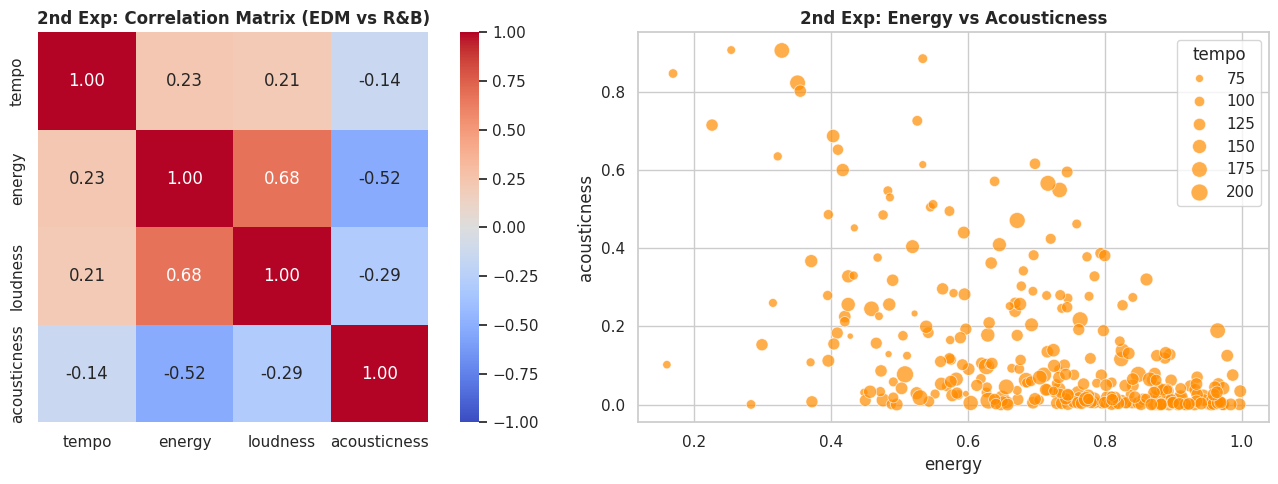

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. 상관계수 행렬 계산 (교안 Seaborn 예제 4)
corr_2nd = df_2nd.corr()
print("=== [02. SciVis - 2차 실험] 음향 특성 상관 행렬 ===")
print(corr_2nd.round(2))

# 2. 시각화: (좌) 히트맵 + (우) 산점도
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_2nd, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("2nd Exp: Correlation Matrix (EDM vs R&B)", fontweight="bold")

sns.scatterplot(data=df_2nd, x="energy", y="acousticness",
                size="tempo", sizes=(20, 150), color="darkorange",
                alpha=0.7, ax=axes[1])
axes[1].set_title("2nd Exp: Energy vs Acousticness", fontweight="bold")

plt.tight_layout()
plt.savefig("/content/step2_scivis_2nd.png", dpi=150, bbox_inches="tight")
plt.show()

=== [03. ML - 2차 실험] K-Means 군집화 결과 ===
반복: 9, Inertia: 10.50, Silhouette: 0.5212
  군집 0: 중심=(energy=0.77, acousticness=0.06), 곡 수 n=230
  군집 1: 중심=(energy=0.50, acousticness=0.41), 곡 수 n=70


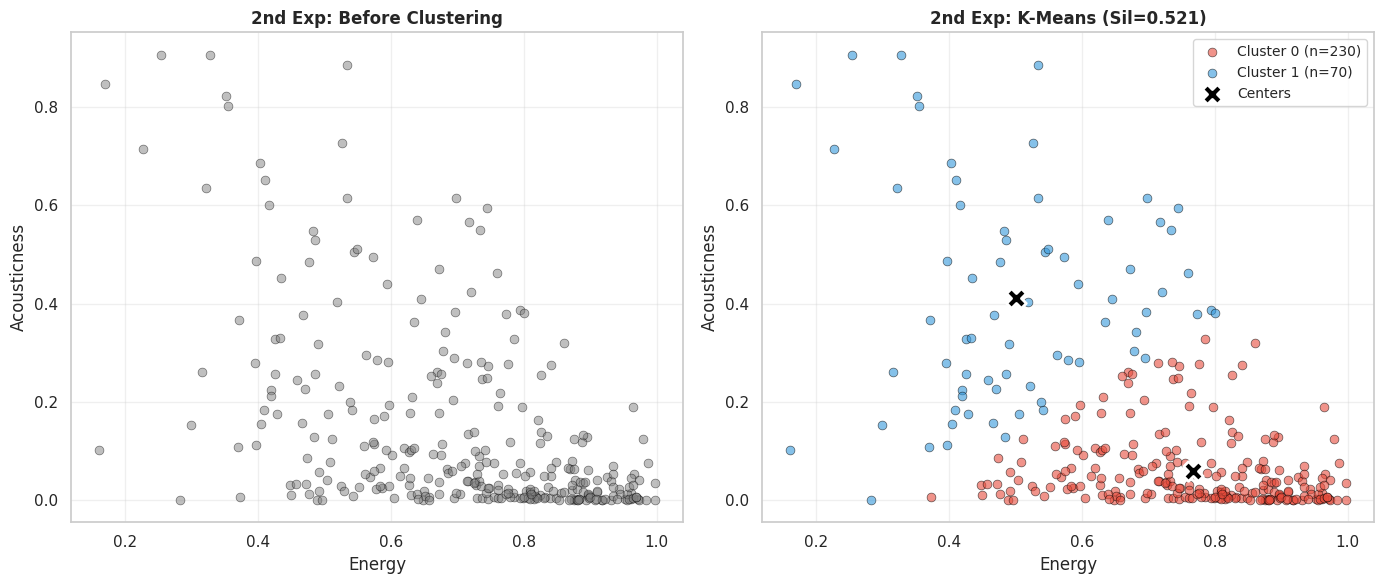

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. 2D 특징 추출
X_2nd = df_2nd[["energy", "acousticness"]].values

# 2. K-Means 모델 학습 (n_clusters=2로 변경, 교안 scikit-learn 예제 4)
kmeans_2nd = KMeans(n_clusters=2, random_state=42, n_init=10)
y_pred_2nd = kmeans_2nd.fit_predict(X_2nd)
centers_2nd = kmeans_2nd.cluster_centers_
sil_2nd = silhouette_score(X_2nd, y_pred_2nd)

print("=== [03. ML - 2차 실험] K-Means 군집화 결과 ===")
print(f"반복: {kmeans_2nd.n_iter_}, Inertia: {kmeans_2nd.inertia_:.2f}, Silhouette: {sil_2nd:.4f}")
for i, c in enumerate(centers_2nd):
    print(f"  군집 {i}: 중심=(energy={c[0]:.2f}, acousticness={c[1]:.2f}), 곡 수 n={np.sum(y_pred_2nd==i)}")

# 3. 군집화 전/후 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#e74c3c', '#3498db']

axes[0].scatter(X_2nd[:, 0], X_2nd[:, 1], c='gray', alpha=0.5, s=40, edgecolors='black', lw=0.5)
axes[0].set_xlabel('Energy'); axes[0].set_ylabel('Acousticness')
axes[0].set_title('2nd Exp: Before Clustering', fontweight='bold'); axes[0].grid(alpha=0.3)

for i in range(2):
    m = (y_pred_2nd == i)
    axes[1].scatter(X_2nd[m, 0], X_2nd[m, 1], c=colors[i], alpha=0.6, s=40,
                    edgecolors='black', lw=0.5, label=f'Cluster {i} (n={m.sum()})')

axes[1].scatter(centers_2nd[:, 0], centers_2nd[:, 1], c='black', marker='X', s=200,
                edgecolors='white', lw=2, zorder=10, label='Centers')
axes[1].set_xlabel('Energy'); axes[1].set_ylabel('Acousticness')
axes[1].set_title(f'2nd Exp: K-Means (Sil={sil_2nd:.3f})', fontweight='bold')
axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/content/step3_kmeans_2nd.png", dpi=150, bbox_inches="tight")
plt.show()